# Xenium Prime 5K Breast — expression-only GNN communication niches

Select the **cccphe** kernel and use **Run All**. This notebook invokes existing project modules to prepare and audit the real inputs, train the current model when needed, and display its results. A complete result with matching configuration is reused. New outputs are independent of archived AE/GNN results and remain on NAS. This is an independent downstream single-tissue analysis; no clinical/phenotype/TLS supervision enters the clinical CCC/Cox mainline.

Current training initializes H and program-activity biases using NMF fitted on at most 8,192 training-block microenvironments (effective CCC features only), then jointly optimizes the GNN and H for at most 5 epochs. NMF fitting is initialization, not encoder pretraining or an extra training loss. Current training uses bounded nonzero-weighted CCC reconstruction + program regularization only (lambda_comp=0, lambda_reg=0.005). The expression-only residual GNN uses 2,048 genes, width 128 and two directed message layers. All retained CCC ligand/receptor complex members are mandatory; training-variance genes fill the remaining budget. Cell-type composition reconstruction is disabled. Restart Kernel / Run All to use this configuration. Results are stored in an independent NAS directory; archived composition-constrained models remain unchanged.

In [1]:
%matplotlib inline
from pathlib import Path
import sys,json
import anndata as ad
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path('/home/xueshuailin/CCC_Phe')
sys.path.insert(0,str(ROOT/'src'))
from phenoniche.gnn.config import GNNConfig
from phenoniche.ccc.config import default_config
from phenoniche.gnn.pipeline import ensure_results
from phenoniche.gnn.reporting import GNNReport
CONFIG=ROOT/'config/gnn.json'
config=GNNConfig.from_json(CONFIG)
OUTPUT=Path(config.output_dir)
pd.set_option('display.max_colwidth',150)
pd.set_option('display.max_rows',200)
def show(fig):
    display(fig)
    plt.close(fig)

## 1. Real data and model configuration

The current LR expression coverage filter is 10%. The encoder receives expression and geometry only. Cell types supply directed CCC labels and downstream annotations only; they are not encoder inputs or composition reconstruction supervision. Every retained CCC ligand/receptor component is included in the 2,048-gene budget. All remaining genes are chosen by normalized expression variance on training physical cells. LR coverage is audited before training, including complex members; missing panel genes or insufficient gene budget raise explicit errors. Expression normalization, feature scales, nonzero weights and the effective CCC mask are fitted only on training spatial blocks. No CollecTRI/NicheNet supervision or regulatory target holdout is used.

In [2]:
input_config=default_config()
adata=ad.read_h5ad(input_config.processed_h5ad,backed='r')
try:
    display(pd.Series({'cells':adata.n_obs,'panel_genes':adata.n_vars,'dataset':adata.uns.get('dataset'),'expression_coverage_fraction':input_config.expression_coverage_fraction}).to_frame('Input'))
finally:
    adata.file.close()
display(pd.Series(config.to_dict()).to_frame('Model configuration'))
print('NAS outputs:',OUTPUT)

,Input
cells,699110
panel_genes,5101
dataset,Xenium_Prime_Breast_Cancer_FFPE
expression_coverage_fraction,0.1


,Model configuration
seed,40700
split_seed,40700
programs,32
hidden,128
encoder_genes,2048
encoder_gene_selection,lr_plus_variance
encoder_depth,2
message_layers,2
dropout,0.1
ccc_nonzero_weight_max,8.0


NAS outputs: /home/nas3/biod/xueshuailin/CCC_Phe/workspace/outputs/microenvironment_gnn_nmf_expr10_5epochs


## 2. Prepare, audit, train/reuse, and infer

Run All constructs/audits the unchanged directed CCC target and applies the repository audit gate. Spatial splits purge shared physical cells. Matching complete results and compatible checkpoints are reused; archived incompatible checkpoints are protected.

NMF initialization is fitted only on training CCC after RMS conditioning; its dictionary is restored to native CCC units and normalized to unit row mass. There is no latent-activity matching stage or alternating optimizer. Xenium training stops after at most 5 epochs and selects the best validation checkpoint within those epochs.

Z = aP, P = Softmax(f(G)), C_hat = ZH. H is nonnegative with unit row sums.

L = L_CCC_weighted + 0.005 L_regularization. For feature f, rho_f is its training nonzero fraction and r_f = clip(sqrt((1-rho_f)/rho_f), 1, 8). Nonzero/zero Huber weights are r_f/1, normalized by (1-rho_f)+rho_f*r_f. The CCC definition and native reconstruction ZH are unchanged. Zero targets remain supervised; this is not an extra loss. Two residual directed message layers retain local cell state. Loss values are averages over cells/features, not total matrix error. Unweighted Huber, conditional nonzero error, feature R², native relative RMSE, and gains over zero/training-mean predictors are reported to assess meaningful improvement. There is no cell-type composition reconstruction loss. Cell composition is used for descriptive downstream diagnostics only.

In [3]:
summary=ensure_results(CONFIG)
report=GNNReport(OUTPUT)
display(report.overview())
display(report.features.head(12))
display(pd.Series(report.data_audit.get('encoder_gene_selection',{})).to_frame('Encoder gene coverage'))
display(pd.Series(summary).to_frame('Saved analysis summary'))
display(pd.Series(json.loads((OUTPUT/'initialization_audit.json').read_text())).to_frame('Training-only NMF initialization'))

Undefined composition for 17 centers with zero physical-pair opportunity; skipping their composition supervision
Static graph inputs resident on cuda:2
Epoch 1/5
Epoch 1: train CCC=0.376558, validation CCC=0.351746, selected loss=0.355237; validation unweighted=0.112348, positive=1.300846, gain vs zero=15.9%
Epoch 2/5
Epoch 2: train CCC=0.354248, validation CCC=0.347553, selected loss=0.351006; validation unweighted=0.115665, positive=1.268114, gain vs zero=16.9%
Epoch 3/5
Epoch 3: train CCC=0.343855, validation CCC=0.346147, selected loss=0.349809; validation unweighted=0.115133, positive=1.257861, gain vs zero=17.3%
Epoch 4/5
Epoch 4: train CCC=0.337639, validation CCC=0.342256, selected loss=0.345846; validation unweighted=0.110577, positive=1.259754, gain vs zero=18.2%
Epoch 5/5
Epoch 5: train CCC=0.333390, validation CCC=0.342575, selected loss=0.346218; validation unweighted=0.112402, positive=1.255294, gain vs zero=18.1%


,Value
Cells / microenvironments,699110
Xenium genes,5101
Fixed directed CCC features,494
Effective training features,447
Expression input genes,2048
Cell-type encoder input,False
LR members in encoder,103
Required LR members,103
Directed message layers,2
Hidden width,128


,feature_id,flat_feature_index,sender,receiver,lr_id,ligand,receptor,ccc
0,0,31701,Endothelial,Endothelial,CommuSpace_HS_00391,APP,FLT1,Endothelial → Endothelial | APP–FLT1
1,1,31974,Endothelial,Endothelial,CommuSpace_HS_01082,CCN1,ITGB3,Endothelial → Endothelial | CCN1–ITGB3
2,2,32155,Endothelial,Endothelial,CommuSpace_HS_01731,COL4A1,CD93,Endothelial → Endothelial | COL4A1–CD93
3,3,32163,Endothelial,Endothelial,CommuSpace_HS_01751,COL4A2,CD93,Endothelial → Endothelial | COL4A2–CD93
4,4,32169,Endothelial,Endothelial,CommuSpace_HS_01767,COL4A2,ITGB3,Endothelial → Endothelial | COL4A2–ITGB3
5,5,32460,Endothelial,Endothelial,CommuSpace_HS_02648,ENG,BMPR2,Endothelial → Endothelial | ENG–BMPR2
6,6,33638,Endothelial,Endothelial,CommuSpace_HS_06138,PECAM1,ITGB3,Endothelial → Endothelial | PECAM1–ITGB3
7,7,33639,Endothelial,Endothelial,CommuSpace_HS_06139,PECAM1,PECAM1,Endothelial → Endothelial | PECAM1–PECAM1
8,8,33776,Endothelial,Endothelial,CommuSpace_HS_06474,PTPRM,PTPRM,Endothelial → Endothelial | PTPRM–PTPRM
9,9,34075,Endothelial,Endothelial,CommuSpace_HS_07380,THBS1,ITGB3,Endothelial → Endothelial | THBS1–ITGB3


,Encoder gene coverage
policy,lr_plus_variance
variance_fit,training physical cells only
requested_genes,2048
selected_genes,2048
required_LR_members,103
LR_members_in_panel,103
LR_members_in_encoder,103
missing_panel_members,[]
missing_encoder_members,[]
CCC_features_fully_covered,494


,Saved analysis summary
composition_undefined_centers,17
composition_to_Z_test_R2,0.269511
composition_only_niche_test_accuracy,0.815757
dominant_niche_test_fraction,0.351977
test_spatial_neighbor_agreement,0.911955
effective_programs,12.552855
maximum_dictionary_cosine,0.435939
dictionary_entropy,3.752359
interpretation,"Single-tissue association diagnostics; composition is downstream descriptive analysis, not evidence of causality or phenotype."
selected_K,5


,Training-only NMF initialization
method,nmf
fit,training spatial blocks only; no validation/test CCC
training_centers,8192
training_rows_sha256,eb68fcc5108381aabe3445a0c70c204e74323535888b883cfc4c968e21f1b626
prototype_features,447
feature_mask_sha256,85ded6513b3331fae57cde9c9eb26527720967a153fe5097d3c2f2714f92eece
seed,40700
iterations,127
max_iter,500
converged,True


## 3. Training curves and held-out CCC reconstruction

Train/validation/test centers do not share physical cells. Only CCC reconstruction and regularization contribute to the training objective.

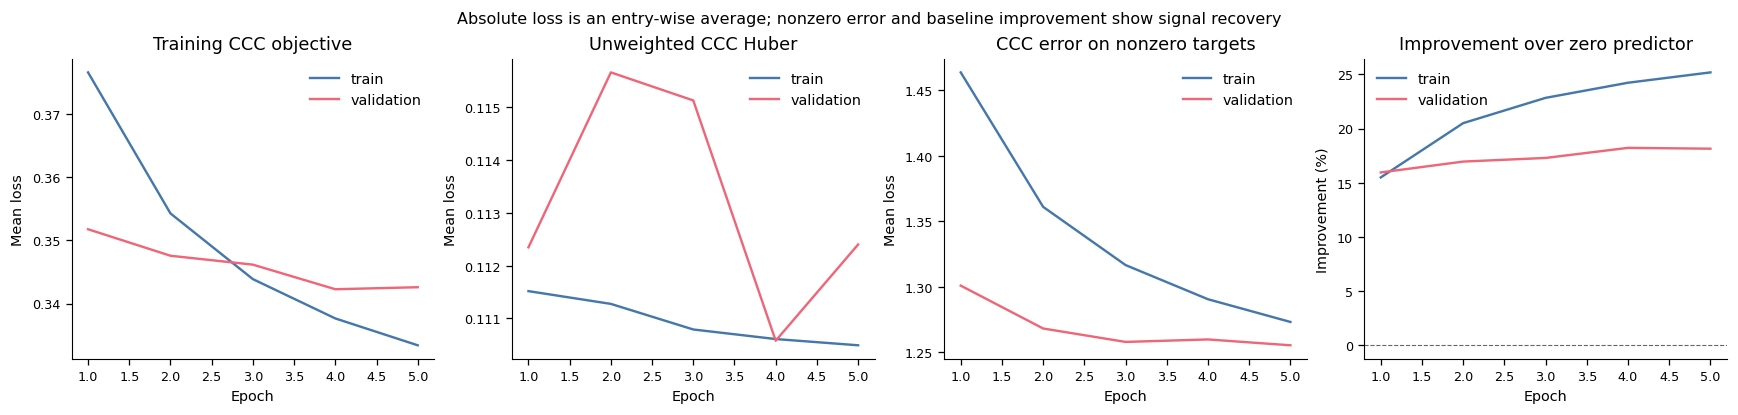

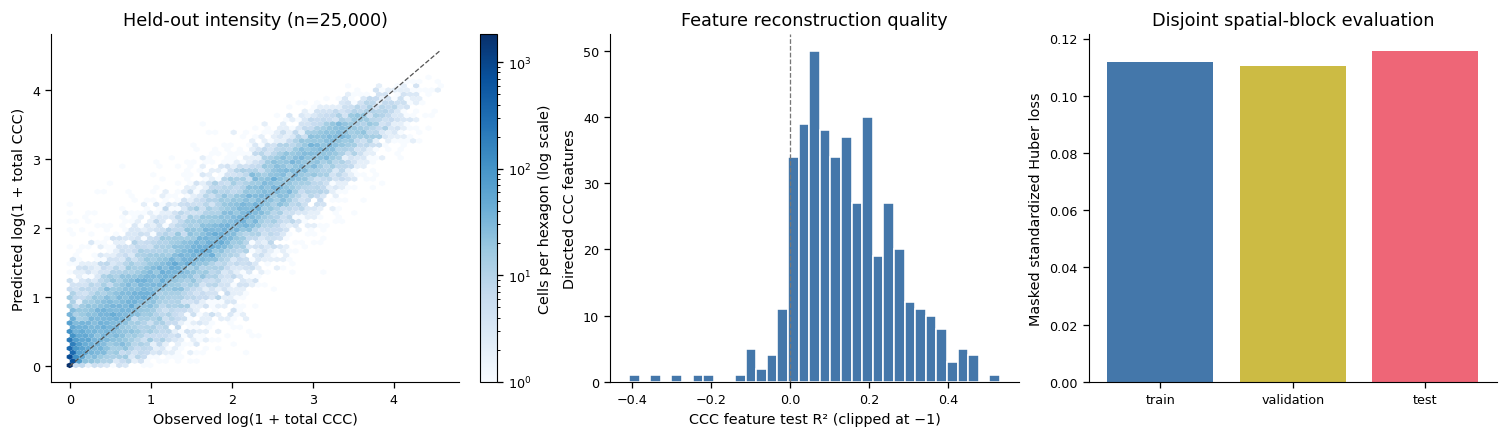

,n,scaled_huber,median_feature_R2,weighted_huber,positive_scaled_huber,zero_scaled_huber,target_nonzero_fraction,zero_predictor_weighted_huber,gain_over_zero_predictor,native_relative_RMSE,train_mean_predictor_weighted_huber,gain_over_train_mean
train,359883.0,0.111829,0.189248,0.332596,1.262066,0.042354,0.056960,0.445571,0.253551,0.822740,0.434600,0.234707
validation,107313.0,0.110577,0.127258,0.342256,1.259754,0.038995,0.058637,0.418481,0.182146,0.843972,0.406998,0.159072
test,112368.0,0.115745,0.128619,0.352650,1.326608,0.039960,0.058901,0.429794,0.179491,0.850044,0.418216,0.156775


,Held-out evaluation
best_epoch,4
validation_loss,0.345846
test,"{'ccc': 0.35265038417586925, 'regularization': 0.7412529493624136, 'ccc_zero_baseline': 0.4297944229824885, 'ccc_mean_baseline': 0.418216389887831..."


In [4]:
show(report.training_curves())
show(report.reconstruction())
display(pd.DataFrame(report.reconstruction_metrics).T)
display(pd.Series(json.loads((OUTPUT/'heldout_metrics.json').read_text())).to_frame('Held-out evaluation'))

## 4. All 32 communication programs and CCC dictionary H

Absolute Z preserves total communication activity; P describes relative communication-program activity. H traces each program to sender → receiver → LR features. The H heatmap highlights representative features; full H is exported as CSV. No composition decoder is trained or shown.

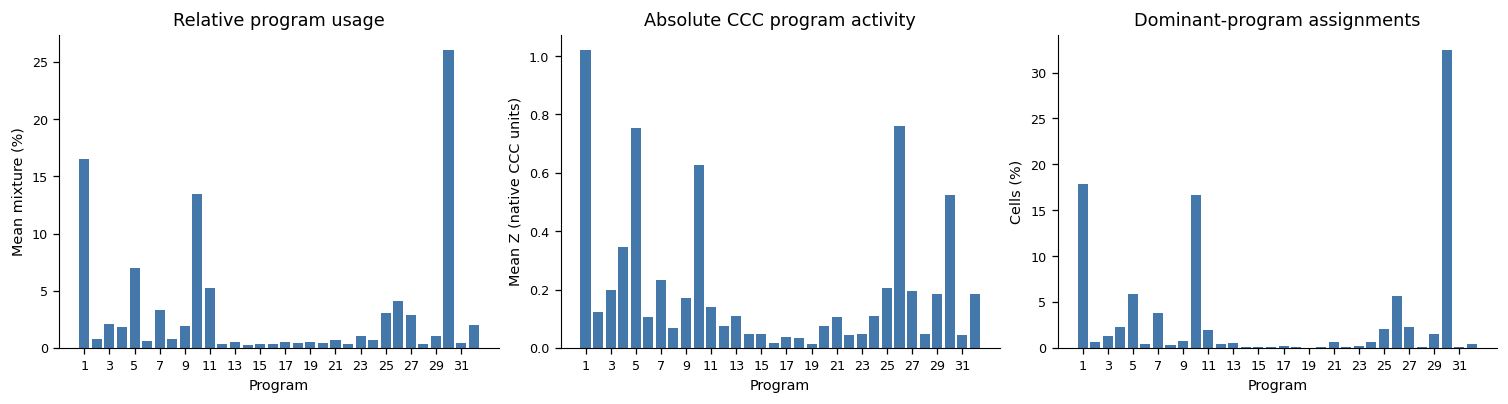

,program,mean_mixture,mean_exposure,dominant_fraction
0,1,0.164774,1.022274,0.179106
1,2,0.007437,0.122284,0.006142
2,3,0.021065,0.199605,0.013397
3,4,0.017983,0.345541,0.022726
4,5,0.070091,0.752632,0.058371
5,6,0.005720,0.105825,0.004424
6,7,0.033333,0.231520,0.038573
7,8,0.007561,0.067743,0.003636
8,9,0.019511,0.172532,0.007268
9,10,0.134873,0.626384,0.166766


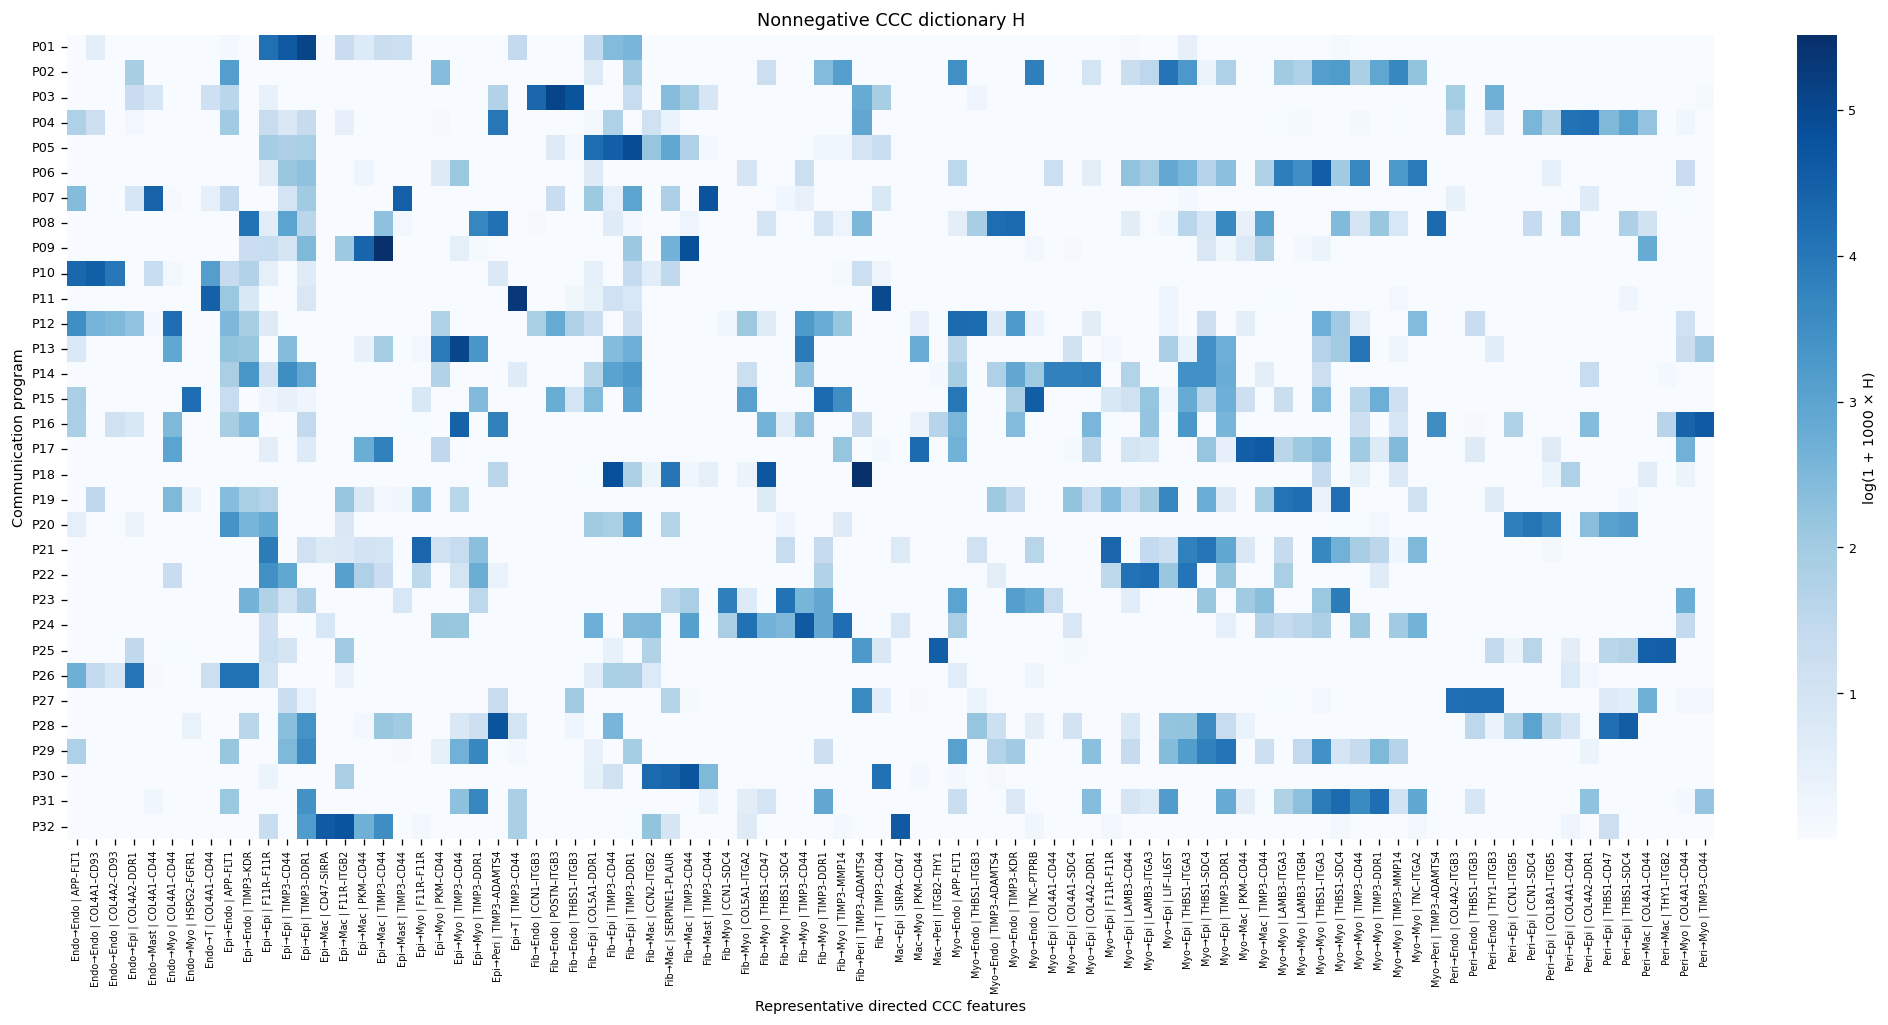

,program,rank,feature_id,ccc,sender,receiver,ligand,receptor,weight
0,1,1,118,Epithelial → Epithelial | TIMP3–DDR1,Epithelial,Epithelial,TIMP3,DDR1,0.160569
1,1,2,117,Epithelial → Epithelial | TIMP3–CD44,Epithelial,Epithelial,TIMP3,CD44,0.100572
2,1,3,99,Epithelial → Epithelial | F11R–F11R,Epithelial,Epithelial,F11R,F11R,0.062148
3,1,4,114,Epithelial → Epithelial | THBS1–SDC4,Epithelial,Epithelial,THBS1,SDC4,0.042484
4,1,5,112,Epithelial → Epithelial | THBS1–CD47,Epithelial,Epithelial,THBS1,CD47,0.036620
15,2,1,328,Myoepithelial → Epithelial | LIF–IL6ST,Myoepithelial,Epithelial,LIF,IL6ST,0.056596
16,2,2,300,Myoepithelial → Endothelial | TNC–PTPRB,Myoepithelial,Endothelial,TNC,PTPRB,0.045413
17,2,3,392,Myoepithelial → Myoepithelial | TIMP3–MMP14,Myoepithelial,Myoepithelial,TIMP3,MMP14,0.038621
18,2,4,387,Myoepithelial → Myoepithelial | THBS1–CD47,Myoepithelial,Myoepithelial,THBS1,CD47,0.036616
19,2,5,159,Epithelial → Myoepithelial | TIMP3–MMP14,Epithelial,Myoepithelial,TIMP3,MMP14,0.033802


In [5]:
fig,usage=report.program_usage();show(fig);display(usage)
show(report.dictionary_heatmap())
display(pd.read_csv(OUTPUT/'programs/top_ccc.csv').groupby('program').head(5))

## 5. Select K = 4–15 and identify communication-defined niches

Clustering is based on communication-program mixture and activity from Z. K is fitted on training blocks and selected on validation blocks; test blocks are reserved for final diagnostics. The selected K maximizes the eligible validation score (tolerance=0), without automatically preferring a coarser near-optimal K. No K=8 is forced. Seed stability refers to clustering seeds, not independent GNN retraining.

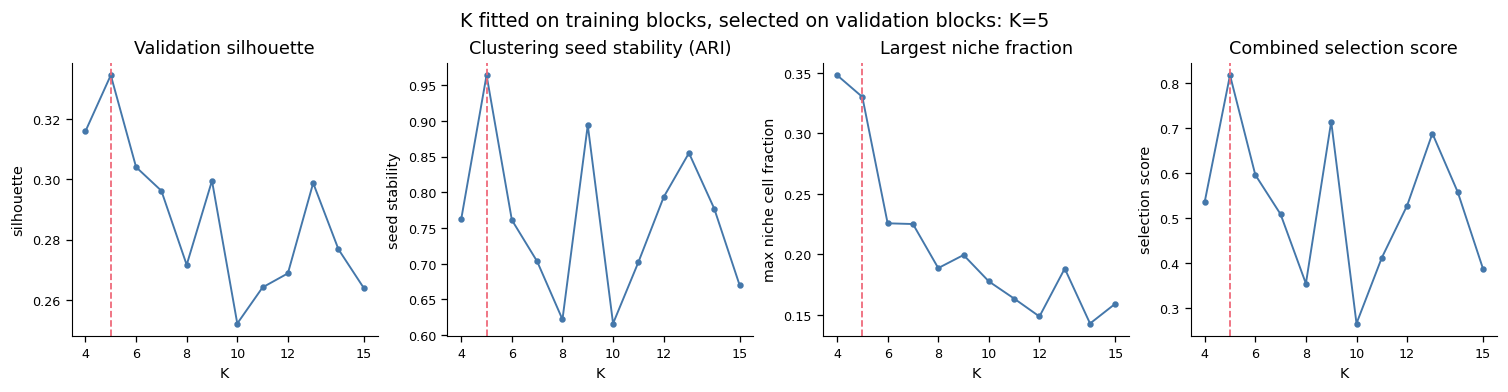

,K,silhouette,seed_stability,max_niche_cell_fraction,tiny_niche_fraction,active_niches,selection_score,eligible,selected
0,4,0.315954,0.762616,0.3480,0.0,4,0.536144,True,False
1,5,0.334547,0.963939,0.3300,0.0,5,0.817544,True,True
2,6,0.304037,0.761039,0.2256,0.0,6,0.596243,True,False
3,7,0.296177,0.703013,0.2250,0.0,7,0.508642,True,False
4,8,0.271598,0.621778,0.1886,0.0,8,0.354772,True,False
5,9,0.299514,0.893921,0.1994,0.0,9,0.714423,True,False
6,10,0.252131,0.616061,0.1776,0.0,10,0.266082,True,False
7,11,0.264123,0.701896,0.1634,0.0,11,0.412147,True,False
8,12,0.268778,0.793127,0.1486,0.0,12,0.527839,True,False
9,13,0.298753,0.854911,0.1882,0.0,13,0.688003,True,False


In [6]:
show(report.k_selection())
display(report.selection)

## 6. Tissue-space maps, individual niches, composition and enrichment

All cell centers use original micrometer coordinates. Enrichment is descriptive within one tissue; overlapping microenvironments are not independent biological replicates. The local composition plot uses the exact pair-weighted composition target.

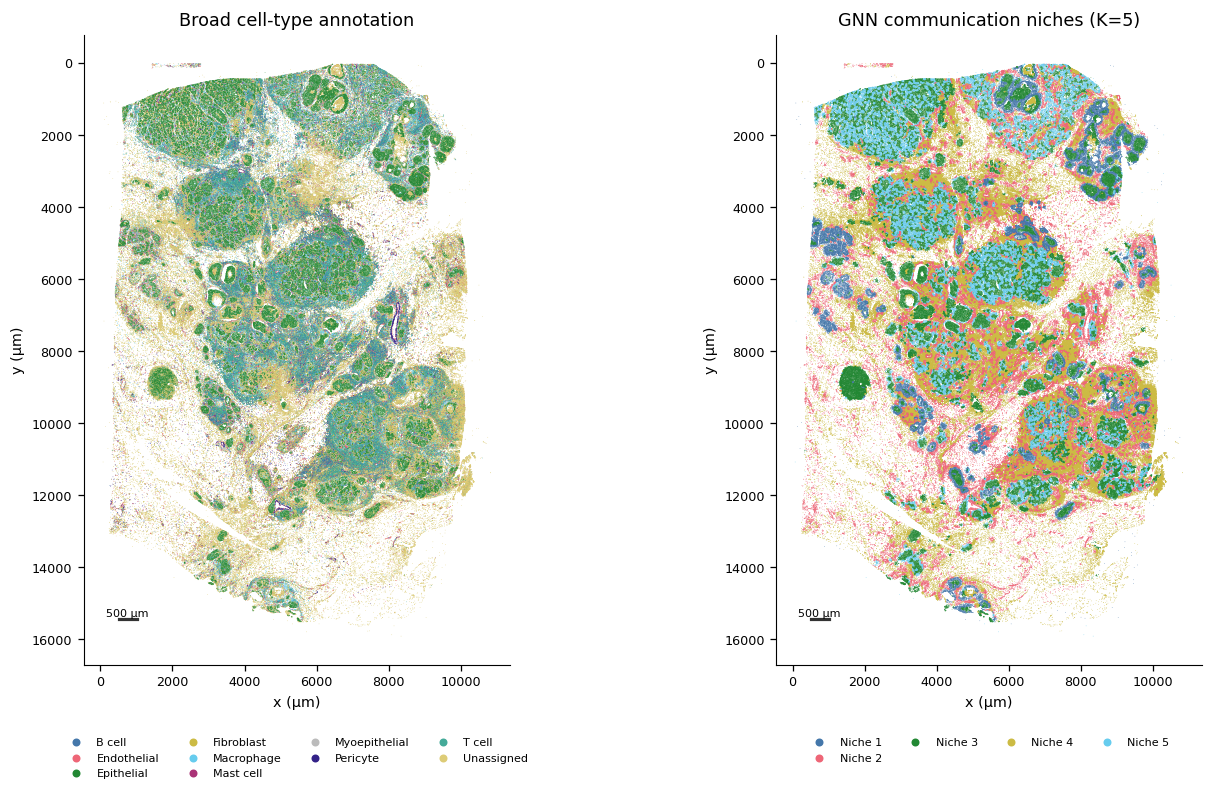

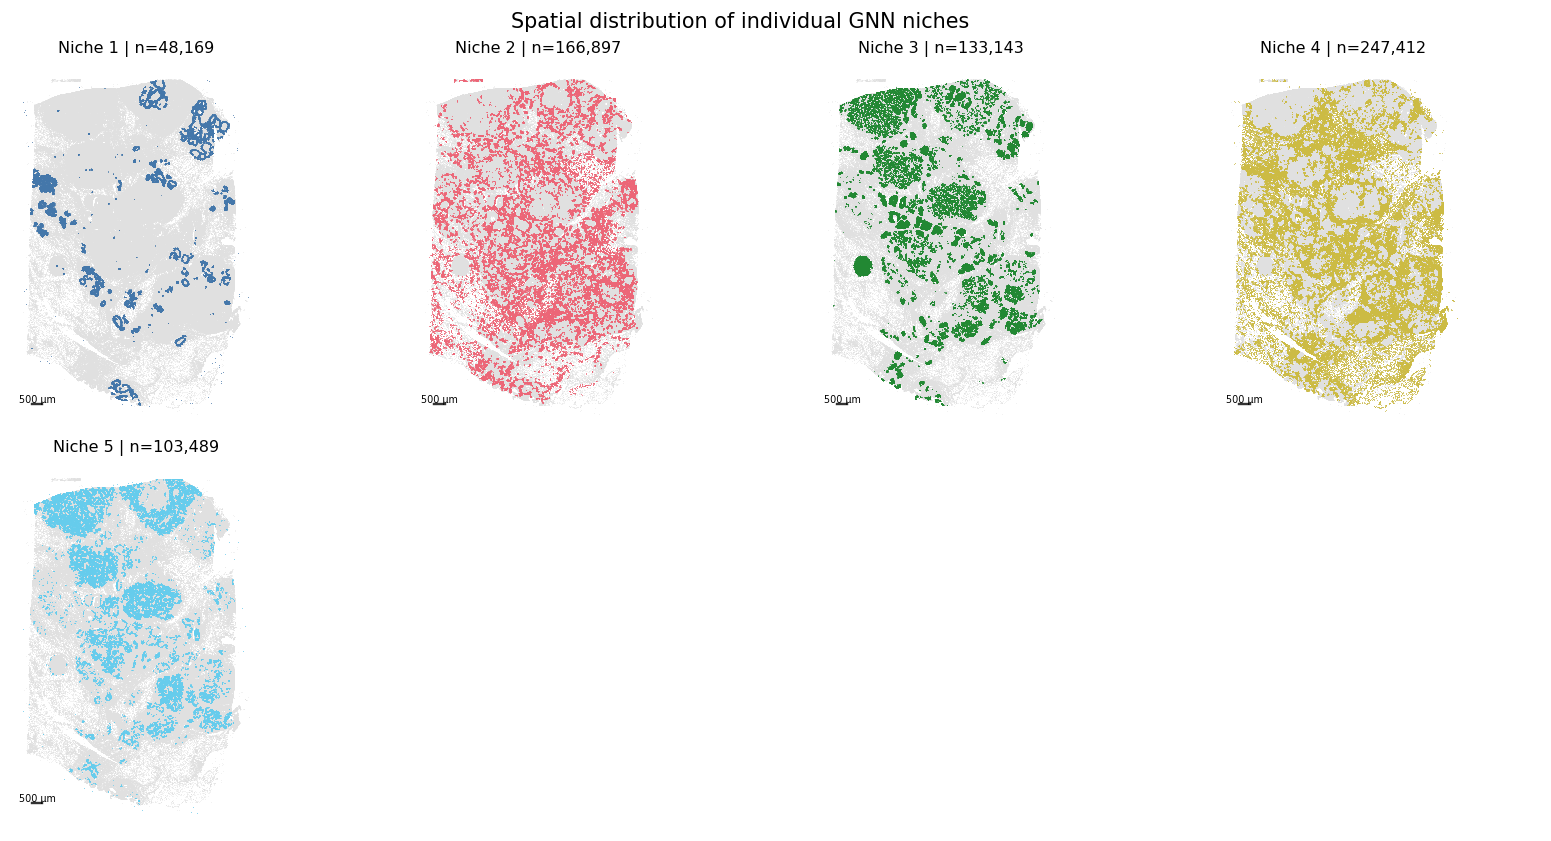

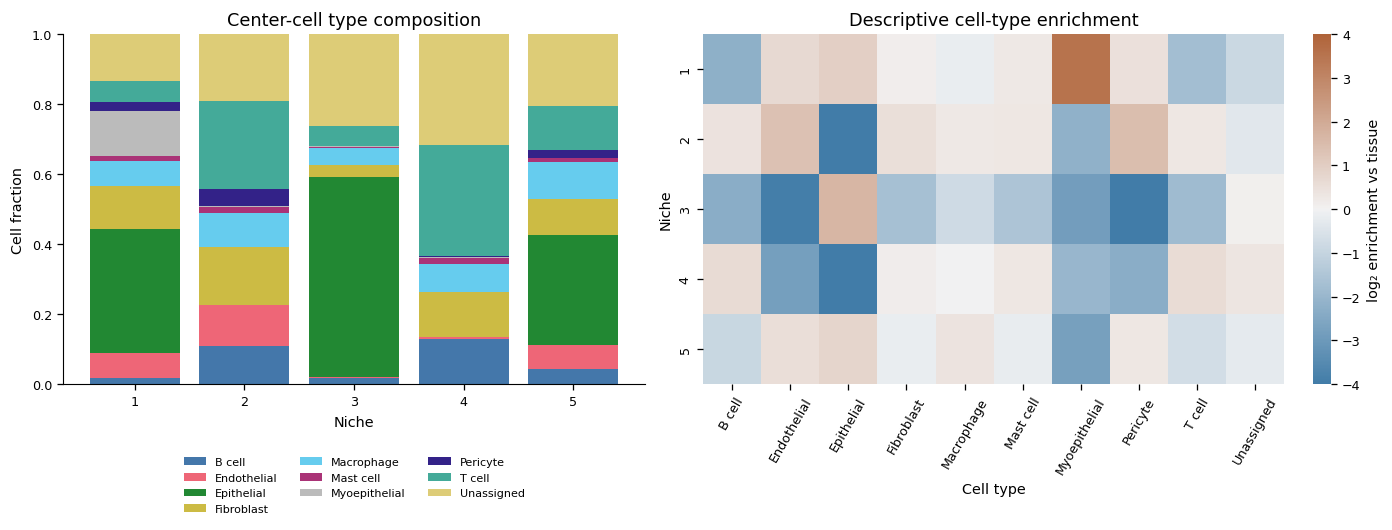

cell_type,B cell,Endothelial,Epithelial,Fibroblast,Macrophage,Mast cell,Myoepithelial,Pericyte,T cell,Unassigned
niche,,,,,,,,,,
1,0.017542,0.073035,0.353049,0.122278,0.071893,0.015259,0.127883,0.025535,0.060246,0.133281
2,0.109810,0.117102,0.000569,0.164730,0.098013,0.015453,0.002349,0.049516,0.251179,0.191280
3,0.016321,0.003012,0.572595,0.034962,0.046844,0.004349,0.001495,0.000466,0.057262,0.262695
4,0.128567,0.006608,0.000934,0.127318,0.081201,0.015428,0.002680,0.003605,0.316775,0.316884
5,0.043338,0.067621,0.316526,0.100977,0.106736,0.010938,0.001594,0.022186,0.125366,0.204717


cell_type,B cell,Endothelial,Epithelial,Fibroblast,Macrophage,Mast cell,Myoepithelial,Pericyte,T cell,Unassigned
niche,,,,,,,,,,
1,-2.232543,0.669765,0.966303,0.095898,-0.186424,0.270766,3.560144,0.486232,-1.771463,-0.891932
2,0.413482,1.350875,-8.307851,0.525838,0.260691,0.288980,-2.206039,1.441605,0.288292,-0.370720
3,-2.336671,-3.929657,1.663949,-1.710359,-0.804384,-1.539977,-2.857792,-5.287776,-1.844761,0.086983
4,0.640987,-2.796240,-7.594903,0.154171,-0.010782,0.286650,-2.015918,-2.337706,0.623035,0.357550
5,-0.927808,0.558653,0.808762,-0.180237,0.383698,-0.209439,-2.764656,0.283404,-0.714272,-0.272770


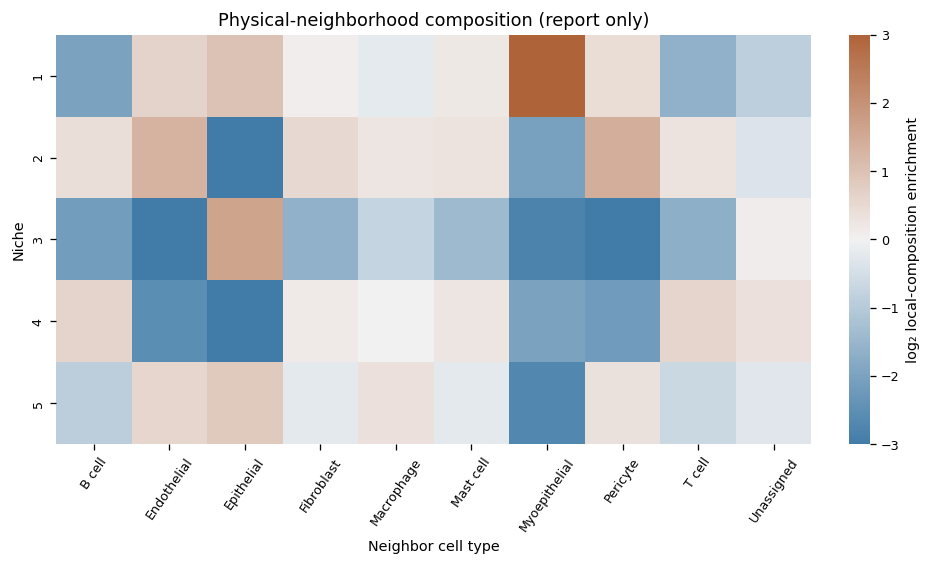

In [7]:
show(report.spatial_overview())
show(report.each_niche())
fig,fraction,enrichment=report.composition();show(fig)
display(fraction)
display(enrichment)
show(report.local_composition())

## 7. Niche × program activity and representative communication

Activity heatmaps use mean Z of assigned cells. Representative niche CCC profiles use training-block soft program contributions, preserving the trained H interpretation. Cell composition is downstream descriptive analysis, not an auxiliary reconstruction task or evidence of causality.

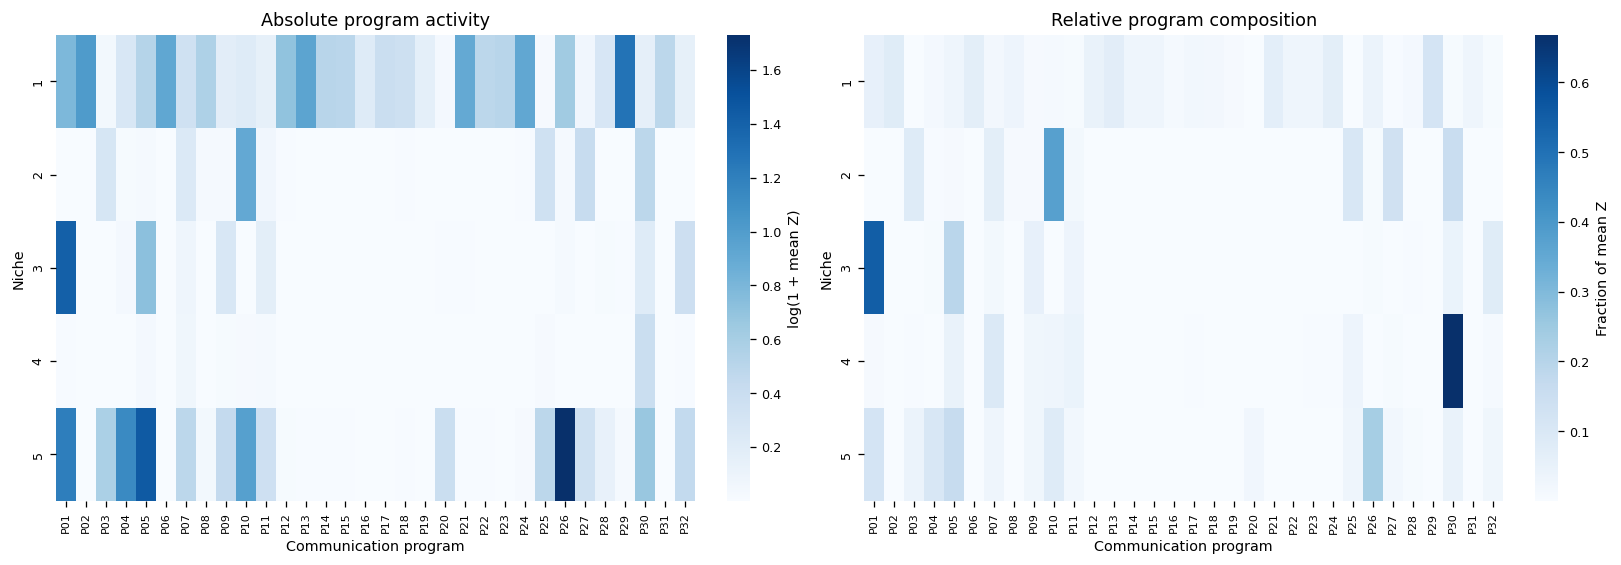

,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10,...,P23,P24,P25,P26,P27,P28,P29,P30,P31,P32
1,1.204349,1.752056,0.048397,0.312183,0.687194,1.517388,0.425223,0.762043,0.206535,0.248313,...,0.662984,1.494998,0.021105,0.881389,0.065580,0.319919,2.606524,0.170344,0.636207,0.165030
2,0.005120,0.000873,0.335713,0.018128,0.032732,0.003072,0.278378,0.034232,0.033306,1.490229,...,0.006749,0.007390,0.423248,0.030946,0.530606,0.001308,0.000773,0.634085,0.002542,0.004720
3,3.087774,0.003156,0.000724,0.038233,1.073200,0.000472,0.091273,0.000988,0.317564,0.004572,...,0.000391,0.003080,0.004128,0.032880,0.000309,0.018623,0.011855,0.246186,0.000407,0.451058
4,0.007162,0.000337,0.003150,0.000773,0.035473,0.000393,0.070207,0.001315,0.019704,0.021394,...,0.002015,0.002739,0.025582,0.000856,0.004160,0.000407,0.000172,0.487402,0.000344,0.007750
5,2.358670,0.006109,0.777370,2.110837,3.254009,0.003377,0.634625,0.044026,0.561119,1.661687,...,0.004499,0.020886,0.628212,4.645441,0.423276,0.144671,0.028091,0.955777,0.001530,0.566323


,niche,cells,leading_programs,representative_CCC
0,1,48169,"P29, P02, P13",Epithelial → Epithelial | TIMP3–DDR1; Myoepithelial → Myoepithelial | THBS1–ITGA3; Epithelial → Myoepithelial | TIMP3–CD44; Myoepithelial → Epithe...
1,2,166897,"P10, P30, P27",Endothelial → Endothelial | COL4A1–CD93; Endothelial → Endothelial | APP–FLT1; Fibroblast → Endothelial | TIMP3–KDR; Pericyte → Endothelial | COL4...
2,3,133143,"P01, P05, P32",Epithelial → Epithelial | TIMP3–DDR1; Epithelial → Epithelial | TIMP3–CD44; Epithelial → Epithelial | F11R–F11R; Fibroblast → Epithelial | TIMP3–D...
3,4,247412,"P30, P10, P07",Fibroblast → Macrophage | TIMP3–CD44; Fibroblast → Macrophage | SERPINE1–PLAUR; Fibroblast → Macrophage | CCN2–ITGB2; Fibroblast → T cell | TIMP3–...
4,5,103489,"P26, P05, P01",Fibroblast → Epithelial | TIMP3–DDR1; Epithelial → Epithelial | TIMP3–DDR1; Fibroblast → Epithelial | TIMP3–CD44; Epithelial → Endothelial | APP–F...


Niche 1: representative sender–receiver–LR


,niche,rank,feature_id,ccc,sender,receiver,ligand,receptor,weight
0,1,1,118,Epithelial → Epithelial | TIMP3–DDR1,Epithelial,Epithelial,TIMP3,DDR1,0.016939
1,1,2,388,Myoepithelial → Myoepithelial | THBS1–ITGA3,Myoepithelial,Myoepithelial,THBS1,ITGA3,0.016631
2,1,3,157,Epithelial → Myoepithelial | TIMP3–CD44,Epithelial,Myoepithelial,TIMP3,CD44,0.014399
3,1,4,336,Myoepithelial → Epithelial | THBS1–SDC4,Myoepithelial,Epithelial,THBS1,SDC4,0.012644
4,1,5,338,Myoepithelial → Epithelial | TIMP3–DDR1,Myoepithelial,Epithelial,TIMP3,DDR1,0.012074


Niche 2: representative sender–receiver–LR


...

Niche 4: representative sender–receiver–LR


,niche,rank,feature_id,ccc,sender,receiver,ligand,receptor,weight
45,4,1,219,Fibroblast → Macrophage | TIMP3–CD44,Fibroblast,Macrophage,TIMP3,CD44,0.061955
46,4,2,215,Fibroblast → Macrophage | SERPINE1–PLAUR,Fibroblast,Macrophage,SERPINE1,PLAUR,0.043623
47,4,3,213,Fibroblast → Macrophage | CCN2–ITGB2,Fibroblast,Macrophage,CCN2,ITGB2,0.037972
48,4,4,253,Fibroblast → T cell | TIMP3–CD44,Fibroblast,T cell,TIMP3,CD44,0.037157
49,4,5,212,Fibroblast → Macrophage | CCN1–ITGB2,Fibroblast,Macrophage,CCN1,ITGB2,0.031445


Niche 5: representative sender–receiver–LR


,niche,rank,feature_id,ccc,sender,receiver,ligand,receptor,weight
60,5,1,206,Fibroblast → Epithelial | TIMP3–DDR1,Fibroblast,Epithelial,TIMP3,DDR1,0.026995
61,5,2,118,Epithelial → Epithelial | TIMP3–DDR1,Epithelial,Epithelial,TIMP3,DDR1,0.022533
62,5,3,205,Fibroblast → Epithelial | TIMP3–CD44,Fibroblast,Epithelial,TIMP3,CD44,0.018554
63,5,4,74,Epithelial → Endothelial | APP–FLT1,Epithelial,Endothelial,APP,FLT1,0.014596
64,5,5,81,Epithelial → Endothelial | TIMP3–KDR,Epithelial,Endothelial,TIMP3,KDR,0.013730


,Diagnostic
composition_undefined_centers,17
composition_to_Z_test_R2,0.269511
composition_only_niche_test_accuracy,0.815757
dominant_niche_test_fraction,0.351977
test_spatial_neighbor_agreement,0.911955
effective_programs,12.552855
maximum_dictionary_cosine,0.435939
dictionary_entropy,3.752359
interpretation,"Single-tissue association diagnostics; composition is downstream descriptive analysis, not evidence of causality or phenotype."


In [8]:
fig,activity=report.niche_programs();show(fig);display(activity)
overview,ccc=report.interpretation();display(overview)
for niche in range(1,report.k+1):
    print(f'Niche {niche}: representative sender–receiver–LR')
    display(ccc.loc[ccc.niche==niche].head(5))
display(pd.Series(json.loads((OUTPUT/'diagnostics.json').read_text())).to_frame('Diagnostic'))

## 8. Comparison with archived CCC-vector AE

Archived AE weights/results remain unchanged. Spatial maps and cell assignment correspondence are descriptive: the archived model used overlapping random folds and a potentially different CCC feature mask. This comparison does not establish comparative generalization or phenotype associations.

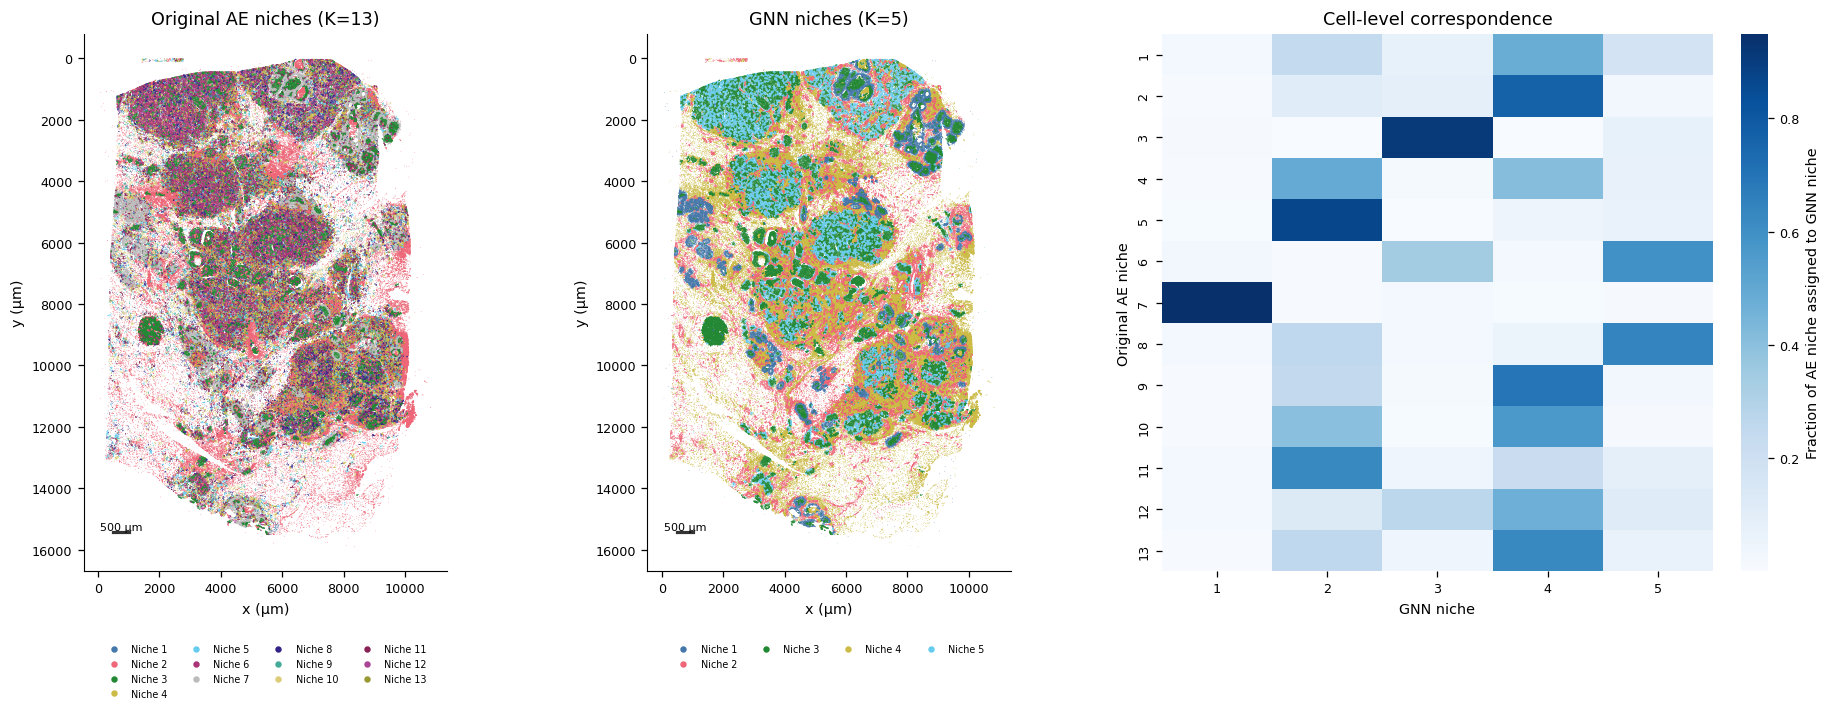

,Value
Cells,699110
Original AE K,13
GNN K,5
Adjusted Rand index,0.248251
Normalized mutual information,0.349041
Comparison scope,Descriptive same-tissue correspondence; original AE used overlapping random folds


Model arrays, native CCC reconstruction, records, tables and PNG/PDF: /home/nas3/biod/xueshuailin/CCC_Phe/workspace/outputs/microenvironment_gnn_nmf_expr10_5epochs


In [9]:
fig,comparison=report.comparison();show(fig);display(comparison)
print('Model arrays, native CCC reconstruction, records, tables and PNG/PDF:',OUTPUT)